In [3]:
import joblib
import matplotlib.pyplot as plt
import numpy as np 
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from pmtwin.config import FD001_SENSORS, Settings
from pmtwin.data import add_rul, load_cmapss
from pmtwin.features import engine_split
from pmtwin.health import HealthModel, persistent_alarm

settings = Settings()
sensors = list(FD001_SENSORS)
train = add_rul(load_cmapss(settings.raw_dir, "FD001").train, settings.rul_cap)
fit_units, val_units, _ = engine_split(train["unit"].unique())
fit = train[train["unit"].isin(fit_units)]
val = train[train["unit"].isin(val_units)]

In [4]:
healthy = fit[fit["cycle"] <= 50]
scaler = StandardScaler().fit(healthy[sensors])
pca = PCA(n_components=0.95).fit(scaler.transform(healthy[sensors]))
print("sensors:", len(sensors), "-> patterns kept:", pca.n_components_)

sensors: 14 -> patterns kept: 12


In [5]:
health = HealthModel(sensors, scaler, pca)
normal = health.scores(val[val["cycle"] <= 50])
health = health.with_limits(np.percentile(normal["t2"], 99), np.percentile(normal["spe"], 99))
print("T2 limit:", round(health.t2_limit, 1), "SPE limit:", round(health.spe_limit, 1))

T2 limit: 25.6 SPE limit: 2.3


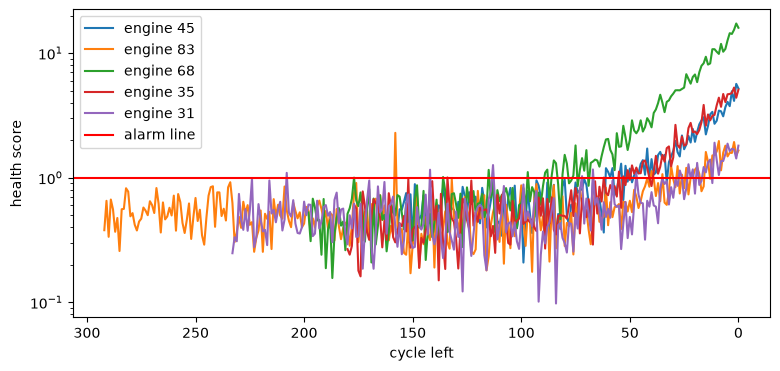

In [6]:
scored = val.join(health.scores(val))
plt.figure(figsize=(9, 4))
for unit in val_units[:5]:
    engine = scored[scored["unit"] == unit]
    plt.plot(engine["rul"], engine["score"], label = f"engine {unit}")
plt.axhline(1, color="red", label="alarm line")
plt.yscale("log")
plt.gca().invert_xaxis()
plt.xlabel("cycle left")
plt.ylabel("health score")
plt.legend()
plt.show()

In [7]:
scored["alarm"] = scored.groupby("unit")["over"].transform(persistent_alarm)
false_alarms = scored[scored["cycle"] <= 50]["alarm"].mean()
first_alarm = scored[scored["alarm"]].groupby("unit")["rul"].max()

print(f"false alarms on healthy cycles: {false_alarms:.1%}")
print("engines that never alarmed:", len(val_units) - len(first_alarm))
print("cycles left at the first alarm:", sorted(first_alarm.tolist()))
print("median warning:", first_alarm.median(), "cycles before failure")

false alarms on healthy cycles: 0.0%
engines that never alarmed: 0
cycles left at the first alarm: [18, 23, 24, 33, 33, 33, 35, 39, 51, 59, 59, 70, 80, 86, 94]
median warning: 39.0 cycles before failure


In [9]:
joblib.dump(health, settings.health_path)

['/home/Adi_mauryaji/Digital Twinning/Predictive-Maintenance-Twin/artifacts/health.joblib']